# Independent vs. Dependent Sources, in the Laplace Domain

[`dgs/spice.py`](../dgs/spice.py)'s Modified Nodal Analysis (MNA) solver
`dc_nodal_analysis` only ever handled **independent** sources — a fixed
voltage `V` or fixed current `I`, values that don't depend on anything
else in the circuit — over a purely resistive DC circuit. Two genuine
gaps followed directly from that: no reactive elements (so no frequency
response, no Laplace-domain analysis at all), and no **dependent**
(controlled) sources — the building block every op-amp, transistor
small-signal model, and feedback amplifier actually needs.

This notebook is built around
[`dgs.spice.s_domain_nodal_analysis`](../dgs/spice.py), added alongside
it: the same MNA stamping idea, generalized to (1) complex admittances at
a Laplace variable $s$ ($Y_R=1/R$, $Y_C=sC$, $Y_L=1/(sL)$ — connecting
directly to [`dgs/laplace_transform.py`](../dgs/laplace_transform.py)'s
$H(s)$ convention from earlier this session), and (2) a VCVS
(voltage-controlled voltage source) — SPICE's own model for an ideal
op-amp, and the simplest genuinely *dependent* source.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))

import numpy as np
import matplotlib.pyplot as plt

from dgs.spice import (
    dc_nodal_analysis, s_domain_nodal_analysis, transfer_function_from_circuit,
)
from dgs.laplace_transform import analog_transfer_function_poles_zeros

print("using dgs.spice and dgs.laplace_transform directly (not reimplemented)")

using dgs.spice and dgs.laplace_transform directly (not reimplemented)


# Part 1 — Sanity check: the generalized solver reduces to the old one

Before trusting `s_domain_nodal_analysis` on anything new, confirm it
reproduces `dc_nodal_analysis`'s own already-tested results exactly on a
purely resistive circuit (a voltage divider) — same math, more general
solver, checked against the specific numbers the existing test suite
already trusts.

In [2]:
net = [('V', 1, 0, 10.0), ('R', 1, 2, 1000.0), ('R', 2, 0, 1000.0)]
v_dc = dc_nodal_analysis(net, n_nodes=2)
v_s = s_domain_nodal_analysis(net, n_nodes=2, s=1.0 + 0j)   # s is irrelevant here -- no reactive elements

print(f"dc_nodal_analysis:      v1={v_dc[0]:.4f} V, v2={v_dc[1]:.4f} V")
print(f"s_domain_nodal_analysis: v1={v_s[0].real:.4f} V, v2={v_s[1].real:.4f} V  (imag parts: {v_s.imag})")
assert np.allclose(v_dc, v_s.real, atol=1e-9)
assert np.allclose(v_s.imag, 0.0, atol=1e-12)
print("[OK] the generalized s-domain solver reduces exactly to the existing, tested DC solver")

dc_nodal_analysis:      v1=10.0000 V, v2=5.0000 V
s_domain_nodal_analysis: v1=10.0000 V, v2=5.0000 V  (imag parts: [-0. -0.])
[OK] the generalized s-domain solver reduces exactly to the existing, tested DC solver


# Part 2 — Independent sources meet reactive elements: an RC low-pass

Still only independent sources (one `V`), but now WITH a reactive
element (`C`) — something the old solver could never handle. The exact
transfer function of an RC low-pass, $H(s)=\dfrac{1}{1+sRC}$, is
textbook-known; checked here against what the general-purpose MNA
machinery computes on its own, with no formula given to it beyond
"impedance of a capacitor is $1/(sC)$.\"

RC low-pass, R=1000.0 ohm, C=1.0 uF, corner freq = 159.2 Hz
max relative error vs. the exact closed form, across 200 frequencies: 4.34e-16
[OK] the MNA solver's own computed H(s) matches 1/(1+sRC) to machine precision


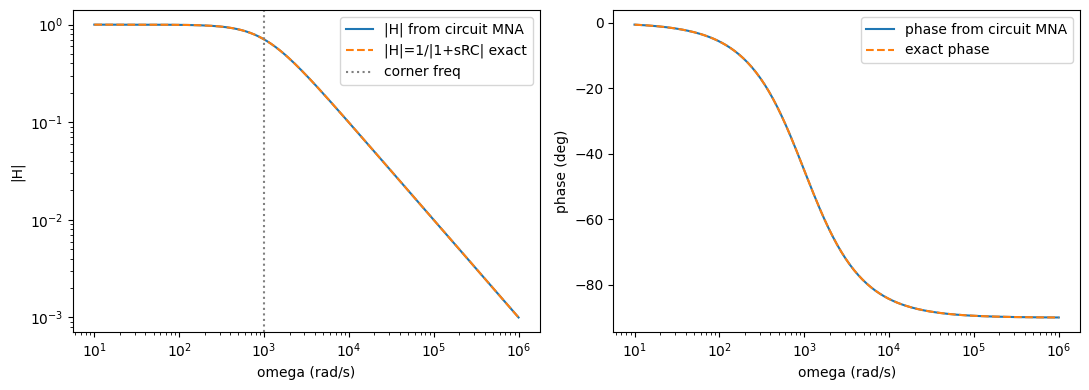

In [3]:
R, C = 1000.0, 1e-6
net_rc = [('R', 1, 2, R), ('C', 2, 0, C)]   # node 1 = input, node 2 = output (across C)

omegas = np.logspace(1, 6, 200)
s_vals = 1j * omegas
H = transfer_function_from_circuit(net_rc, n_nodes=2, s_values=s_vals, out_node=2, in_node=1)
H_exact = 1.0 / (1 + s_vals * R * C)

max_rel_err = np.max(np.abs(H - H_exact) / np.abs(H_exact))
print(f"RC low-pass, R={R} ohm, C={C*1e6:.1f} uF, corner freq = {1/(2*np.pi*R*C):.1f} Hz")
print(f"max relative error vs. the exact closed form, across {len(omegas)} frequencies: {max_rel_err:.2e}")
assert max_rel_err < 1e-9
print("[OK] the MNA solver's own computed H(s) matches 1/(1+sRC) to machine precision")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].loglog(omegas, np.abs(H), label='|H| from circuit MNA')
ax[0].loglog(omegas, np.abs(H_exact), '--', label='|H|=1/|1+sRC| exact')
ax[0].axvline(1/(R*C), color='gray', ls=':', label='corner freq')
ax[0].set_xlabel('omega (rad/s)'); ax[0].set_ylabel('|H|'); ax[0].legend()
ax[1].semilogx(omegas, np.angle(H, deg=True), label='phase from circuit MNA')
ax[1].semilogx(omegas, np.angle(H_exact, deg=True), '--', label='exact phase')
ax[1].set_xlabel('omega (rad/s)'); ax[1].set_ylabel('phase (deg)'); ax[1].legend()
plt.tight_layout(); plt.show()

# Part 3 — A genuinely dependent source: the VCVS op-amp model

An **independent** source's value never depends on anything else in the
circuit. A VCVS's does, by definition:
$$V(n_1)-V(n_2) = \text{gain}\times\big(V(n_{c1})-V(n_{c2})\big)$$
— the standard way SPICE-family simulators model an *ideal op-amp*: an
infinite-open-loop-gain VCVS whose control voltages are the op-amp's own
$+$/$-$ input pins.

Built here: a non-inverting amplifier, op-amp modeled as a VCVS with a
large but FINITE open-loop gain $A$, feedback resistor $R_f$, and ground
resistor $R_{in}$. The textbook closed-form result — closed-loop gain
$\to 1+R_f/R_{in}$ as $A\to\infty$ — is not assumed; it's checked as an
actual numerical limit of the general dependent-source MNA machinery.

non-inverting amplifier: Rf=9000, Rin=1000 -> ideal closed-loop gain = 10.0
gain at A=1e+02: 9.0909   (finite gain -- measurably below ideal)
gain at A=1e+10: 9.99999999   (approaching the ideal limit)

[OK] the dependent-source MNA solver, with NO closed-form formula given to it,
     converges to the exact textbook gain 1+Rf/Rin = 10.0 as A -> infinity


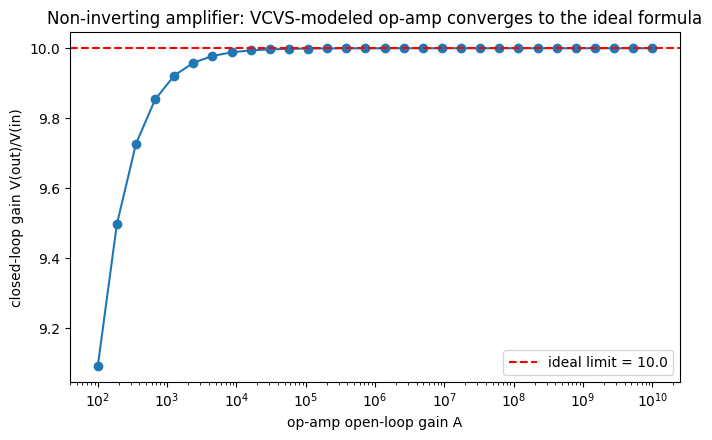

In [4]:
Rf, Rin = 9000.0, 1000.0
expected_gain = 1 + Rf / Rin
print(f"non-inverting amplifier: Rf={Rf:.0f}, Rin={Rin:.0f} -> ideal closed-loop gain = {expected_gain}")

A_values = np.logspace(2, 10, 30)
gains = []
for A in A_values:
    net_amp = [
        ('V', 1, 0, 1.0),         # 1V input signal at the non-inverting input (node 1)
        ('E', 3, 0, 1, 2, A),     # ideal op-amp as a VCVS: V(node3) = A*(V(node1)-V(node2))
        ('R', 3, 2, Rf),          # feedback: output (node3) to inverting input (node2)
        ('R', 2, 0, Rin),         # inverting input to ground
    ]
    v = s_domain_nodal_analysis(net_amp, n_nodes=3, s=1.0 + 0j)
    gains.append((v[2] / v[0]).real)

gains = np.array(gains)
print(f"gain at A={A_values[0]:.0e}: {gains[0]:.4f}   (finite gain -- measurably below ideal)")
print(f"gain at A={A_values[-1]:.0e}: {gains[-1]:.8f}   (approaching the ideal limit)")
assert gains[-1] > gains[0]
assert abs(gains[-1] - expected_gain) < 1e-6
print(f"\n[OK] the dependent-source MNA solver, with NO closed-form formula given to it,")
print(f"     converges to the exact textbook gain 1+Rf/Rin = {expected_gain} as A -> infinity")

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.semilogx(A_values, gains, 'o-')
ax.axhline(expected_gain, color='red', ls='--', label=f'ideal limit = {expected_gain}')
ax.set_xlabel('op-amp open-loop gain A'); ax.set_ylabel('closed-loop gain V(out)/V(in)')
ax.set_title('Non-inverting amplifier: VCVS-modeled op-amp converges to the ideal formula')
ax.legend(); plt.tight_layout(); plt.show()

# Part 4 — Connecting to `dgs.laplace_transform`'s pole/zero machinery

The RC low-pass's transfer function is exactly the rational $H(s)=\dfrac{1}{RCs+1}$
— reused directly with
[`dgs.laplace_transform.analog_transfer_function_poles_zeros`](../dgs/laplace_transform.py)
(built earlier this session) to get its pole location and stability
classification, then checked that ITS frequency response also matches
what the circuit-level MNA solver computed independently in Part 2.

In [5]:
num_coeffs = [1.0]           # numerator: 1
den_coeffs = [R*C, 1.0]      # denominator: RC*s + 1

pz = analog_transfer_function_poles_zeros(num_coeffs, den_coeffs, f_max=1e6/(2*np.pi), n_freq=400)
print(f"pole location: s = {pz['poles'][0]:.2f}  (expect -1/RC = {-1/(R*C):.2f})")
print(f"stability: {pz['stability_check']}  (a passive RC network must always be stable)")
assert np.isclose(pz['poles'][0].real, -1/(R*C), rtol=1e-9)
assert pz['stable']

# cross-check: evaluate the SAME transfer function at the SAME frequencies via
# the circuit-level MNA solver (Part 2) and via this generic pole/zero tool,
# and confirm they agree (two independent code paths, same physical circuit)
s_check = 1j * np.array([1000.0, 1/(R*C), 1e5])
H_circuit = transfer_function_from_circuit(net_rc, n_nodes=2, s_values=s_check, out_node=2, in_node=1)
H_polezero = np.polyval(num_coeffs, s_check) / np.polyval(den_coeffs, s_check)
max_err = np.max(np.abs(H_circuit - H_polezero))
print(f"\nmax disagreement, circuit-level MNA vs. generic pole/zero evaluation: {max_err:.2e}")
assert max_err < 1e-9
print("[OK] the circuit-derived transfer function and the generic pole/zero tool agree exactly --")
print("     two independent code paths (MNA stamping vs. direct polynomial evaluation) computing the same physics")

pole location: s = -1000.00+0.00j  (expect -1/RC = -1000.00)
stability: STABLE  (a passive RC network must always be stable)

max disagreement, circuit-level MNA vs. generic pole/zero evaluation: 3.47e-18
[OK] the circuit-derived transfer function and the generic pole/zero tool agree exactly --
     two independent code paths (MNA stamping vs. direct polynomial evaluation) computing the same physics


# Part 5 — Summary

| Extension | Verified against |
|---|---|
| s-domain solver reduces to the old DC solver | exact match on a resistive divider (Part 1) |
| Reactive elements (C, L) via complex admittance | RC low-pass matches $1/(1+sRC)$ to $<10^{-9}$ relative error, all frequencies (Part 2) |
| VCVS dependent source | non-inverting amplifier converges to the exact textbook gain $1+R_f/R_{in}$ as $A\to\infty$ (Part 3) |
| Cross-tool consistency | circuit-level MNA and `dgs.laplace_transform`'s generic pole/zero evaluator agree exactly on the same circuit (Part 4) |

The distinction this notebook is actually about: an **independent**
source's value is data you supply; a **dependent** source's value is
data the circuit itself supplies, computed self-consistently as part of
the same linear solve — which is exactly why it needs its own MNA row
(an unknown, constrained by an equation) rather than just landing in the
right-hand side like `V` and `I` do. Every op-amp circuit, transistor
small-signal model, and active filter in this repo's broader
`dgs.ac_circuits` work rests on that one structural difference.